# Social Media and Student Wellbeing

This project looks at how students' social media habits relate to their sleep, stress, mental health and grades.

**About this project:** I made this project to study data analysis with Python. It is my portfolio project for Codecademy's Learn Python for Data Science path.

**Dataset:** Each row is one student, with their main platform, daily usage, sleep, stress, mental health score, GPA and the overall impact social media has on them.

**Data source:** "Impact of Social Media on Life" by harishyadav0506, published on Kaggle. You can find it here: [Impact of Social Media on Life on Kaggle](https://www.kaggle.com/datasets/harishyadav0506/impact-of-social-media-on-life). I used it for study purposes only and do not own the data.

**Tools:** Python, pandas, matplotlib, Jupyter Notebook

**Steps in this notebook:**
1. Project goals and data questions
2. Load the data
3. Inspect the data
4. Clean the data
5. Prepare the data (new columns and merges)
6. Exploratory data analysis
7. Key findings
8. Limitations and next steps

## 1. Project goals and data questions

My background is in cyberpsychology, so I wanted to explore a question I care about: is heavy social media use linked to worse wellbeing in students?

I will try to answer these questions:

1. How much time do students spend on social media, and which platforms do they use most?
2. Is heavier daily use linked to less sleep, more stress, lower mental health and lower grades?
3. Does using social media late at night affect sleep?
4. How does social comparison relate to stress and mental health?
5. Which platforms are most often linked to a harmful or a beneficial overall impact?

## 2. Load the data

The first time this runs, it downloads the dataset from Kaggle and saves a copy in the project folder. After that it reads the local copy. For this project, I got help from Claude, when I felt like I was stuck or didn't feel confident that my syntax was right.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

# Chart settings used throughout the notebook
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "axes.axisbelow": True,
})
MAIN_COLOUR = "#2a78d6"

LOCAL_FILE = "Social_media_impact_on_life.csv"

if os.path.exists(LOCAL_FILE):
    df_raw = pd.read_csv(LOCAL_FILE)
else:
    import kagglehub
    path = kagglehub.dataset_download("harishyadav0506/impact-of-social-media-on-life")
    df_raw = pd.read_csv(os.path.join(path, LOCAL_FILE))
    df_raw.to_csv(LOCAL_FILE, index=False)  # keep a copy in the project folder

df_raw.head()

Matplotlib is building the font cache; this may take a moment.


,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


## 3. Inspect the data

Before cleaning, I check the size of the dataset, the data types, missing values, duplicates and whether the numbers look sensible.

In [2]:
# Number of rows and columns, and the data type of each column
print("Rows, columns:", df_raw.shape)
df_raw.info()

Rows, columns: (4500, 16)
<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4500 non-null   str    
 1   Age                          4500 non-null   int64  
 2   Gender                       4500 non-null   str    
 3   Academic_Level               4500 non-null   str    
 4   Primary_Platform             4500 non-null   str    
 5   Daily_Usage_Hours            4500 non-null   float64
 6   Weekend_Extra_Hours          4500 non-null   float64
 7   Device_Type                  4500 non-null   str    
 8   Sleep_Duration_Hours         4500 non-null   float64
 9   Sleep_Quality_Score          4500 non-null   int64  
 10  Late_Night_Usage             4500 non-null   bool   
 11  Social_Comparison_Frequency  4500 non-null   str    
 12  Perceived_Stress_Score       4454 non-null   float64
 13  Men

In [3]:
# Missing values in each column
df_raw.isna().sum()

Student_ID                      0
Age                             0
Gender                          0
Academic_Level                  0
Primary_Platform                0
Daily_Usage_Hours               0
Weekend_Extra_Hours             0
Device_Type                     0
Sleep_Duration_Hours            0
Sleep_Quality_Score             0
Late_Night_Usage                0
Social_Comparison_Frequency     0
Perceived_Stress_Score         46
Mental_Health_Index             0
Academic_Performance_GPA       85
Overall_Impact                  0
dtype: int64

In [4]:
# Duplicate rows and duplicate student IDs
print("Duplicate rows:", df_raw.duplicated().sum())
print("Duplicate student IDs:", df_raw["Student_ID"].duplicated().sum())

Duplicate rows: 0
Duplicate student IDs: 0


In [5]:
# Summary statistics for the numeric columns (look for impossible values)
df_raw.describe()

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
count,4500.000000,4500.000000,4500.000000,4500.000000,4500.000000,4454.000000,4500.000000,4415.000000
mean,18.703333,5.295933,1.796844,6.701333,2.472000,13.512124,79.873111,3.429282
std,1.981182,2.604497,0.699245,1.189998,1.030484,7.072859,12.876044,0.392662
min,15.000000,0.900000,0.000000,3.000000,1.000000,0.000000,32.000000,1.900000
25%,17.000000,3.400000,1.300000,6.000000,2.000000,9.000000,72.000000,3.200000
50%,19.000000,4.700000,1.800000,6.800000,3.000000,13.000000,82.000000,3.460000
75%,20.000000,6.600000,2.300000,7.500000,3.000000,18.000000,89.000000,3.720000
max,26.000000,14.000000,4.500000,10.500000,5.000000,40.000000,98.000000,4.000000


In [6]:
# The categories in each text column (look for typos or inconsistent labels)
for col in df_raw.select_dtypes(include=["object", "string"]).columns.drop("Student_ID"):
    print(f"--- {col} ---")
    print(df_raw[col].value_counts(dropna=False), "\n")

--- Gender ---
Gender
Female               2234
Male                 2051
Non-Binary            122
Prefer not to say      93
Name: count, dtype: int64 

--- Academic_Level ---
Academic_Level
Undergraduate    2777
High School      1477
Postgraduate      246
Name: count, dtype: int64 

--- Primary_Platform ---
Primary_Platform
Instagram      1453
TikTok         1226
YouTube         818
Snapchat        472
Reddit          229
X (Twitter)     206
LinkedIn         96
Name: count, dtype: int64 

--- Device_Type ---
Device_Type
Smartphone    3775
Laptop/PC      596
Tablet         129
Name: count, dtype: int64 

--- Social_Comparison_Frequency ---
Social_Comparison_Frequency
Sometimes     1594
Frequently    1248
Rarely         766
Always         632
Never          260
Name: count, dtype: int64 

--- Overall_Impact ---
Overall_Impact
Beneficial    3681
Neutral        654
Negative       165
Name: count, dtype: int64 



## 4. Clean the data

Cleaning steps:
1. Remove duplicate rows and duplicate student IDs.
2. Remove extra spaces from text columns.
3. Make sure `Late_Night_Usage` is stored as True/False.
4. Fill missing numeric values with the column median, and missing text values with "Unknown".
5. Remove rows with impossible values (for example more than 24 hours of use in a day, or a GPA above 4).

I work on a copy called `df` so the raw data stays unchanged.

In [7]:
df = df_raw.copy()
rows_before = len(df)

# 1. Duplicates
df = df.drop_duplicates()
df = df.drop_duplicates(subset="Student_ID")

# 2. Extra spaces in text columns
text_cols = df.select_dtypes(include=["object", "string"]).columns.drop("Student_ID")
for col in text_cols:
    df[col] = df[col].str.strip()

# 3. Late night usage as True/False
if df["Late_Night_Usage"].dtype != bool:
    df["Late_Night_Usage"] = (
        df["Late_Night_Usage"].astype(str).str.strip().str.lower()
        .map({"true": True, "false": False, "yes": True, "no": False, "1": True, "0": False})
    )

# 4. Missing values
numeric_cols = df.select_dtypes(include="number").columns
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())
for col in text_cols:
    df[col] = df[col].fillna("Unknown")
df["Late_Night_Usage"] = df["Late_Night_Usage"].fillna(False).astype(bool)

# 5. Impossible values
valid = (
    df["Age"].between(10, 100)
    & df["Daily_Usage_Hours"].between(0, 24)
    & df["Weekend_Extra_Hours"].between(0, 24)
    & df["Sleep_Duration_Hours"].between(0, 24)
    & df["Academic_Performance_GPA"].between(0, 4)
)
print("Rows with impossible values removed:", (~valid).sum())
df = df[valid].reset_index(drop=True)

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(df))
print("Missing values left:", df.isna().sum().sum())

Rows with impossible values removed: 0
Rows before cleaning: 4500
Rows after cleaning: 4500
Missing values left: 0


## 5. Prepare the data

To answer my questions I add some new columns:

- `Weekend_Daily_Hours`: daily use plus the extra weekend hours.
- `Usage_Group`: Light (under 3 hours a day), Moderate (3 to 6 hours) or Heavy (over 6 hours).
- `Low_Sleep`: True if the student sleeps less than 7 hours, the minimum usually recommended for young adults.

I also use two **merges**:

1. A small lookup table turns `Social_Comparison_Frequency` into a number from 0 (Never) upwards, so I can measure how it relates to other numbers.
2. A platform summary table (average daily hours per platform) is merged back so each student can be compared with other users of the same platform.

In [8]:
# New columns
df["Weekend_Daily_Hours"] = df["Daily_Usage_Hours"] + df["Weekend_Extra_Hours"]

df["Usage_Group"] = pd.cut(
    df["Daily_Usage_Hours"],
    bins=[0, 3, 6, 24],
    labels=["Light (<3h)", "Moderate (3-6h)", "Heavy (>6h)"],
    include_lowest=True,
)

df["Low_Sleep"] = df["Sleep_Duration_Hours"] < 7

df[["Daily_Usage_Hours", "Weekend_Daily_Hours", "Usage_Group", "Sleep_Duration_Hours", "Low_Sleep"]].head()

,Daily_Usage_Hours,Weekend_Daily_Hours,Usage_Group,Sleep_Duration_Hours,Low_Sleep
0,7.5,9.0,Heavy (>6h),5.9,True
1,4.6,5.9,Moderate (3-6h),7.9,False
2,10.9,12.6,Heavy (>6h),5.2,True
3,6.0,8.3,Moderate (3-6h),7.6,False
4,3.3,5.9,Moderate (3-6h),7.6,False


In [9]:
# Merge 1: lookup table for social comparison frequency
# Order from least to most frequent. Any label not in this list is added at the end.
comparison_order = ["Never", "Rarely", "Sometimes", "Often", "Frequently", "Always"]
present = list(df["Social_Comparison_Frequency"].unique())
comparison_order = [c for c in comparison_order if c in present] + [c for c in present if c not in comparison_order]

comparison_lookup = pd.DataFrame({
    "Social_Comparison_Frequency": comparison_order,
    "Comparison_Score": range(len(comparison_order)),
})

df = df.merge(comparison_lookup, on="Social_Comparison_Frequency", how="left")
comparison_lookup

,Social_Comparison_Frequency,Comparison_Score
0,Never,0
1,Rarely,1
2,Sometimes,2
3,Frequently,3
4,Always,4


In [10]:
# Merge 2: platform summary table merged back onto each student
platform_summary = (
    df.groupby("Primary_Platform")
    .agg(
        Platform_Users=("Student_ID", "count"),
        Platform_Avg_Hours=("Daily_Usage_Hours", "mean"),
    )
    .reset_index()
)

df = df.merge(platform_summary, on="Primary_Platform", how="left")

# How much more (or less) each student uses social media than others on the same platform
df["Hours_vs_Platform_Avg"] = (df["Daily_Usage_Hours"] - df["Platform_Avg_Hours"]).round(2)

df[["Student_ID", "Primary_Platform", "Daily_Usage_Hours", "Platform_Avg_Hours", "Hours_vs_Platform_Avg"]].head()

,Student_ID,Primary_Platform,Daily_Usage_Hours,Platform_Avg_Hours,Hours_vs_Platform_Avg
0,STU_2024000,Snapchat,7.5,5.457415,2.04
1,STU_2024001,Instagram,4.6,5.261390,-0.66
2,STU_2024002,TikTok,10.9,5.330995,5.57
3,STU_2024003,YouTube,6.0,5.248289,0.75
4,STU_2024004,LinkedIn,3.3,5.267708,-1.97


## 6. Exploratory data analysis

### Question 1: How much time do students spend on social media, and on which platforms?

Average daily use: 5.3 hours
Median daily use: 4.7 hours
Average on a weekend day: 7.1 hours


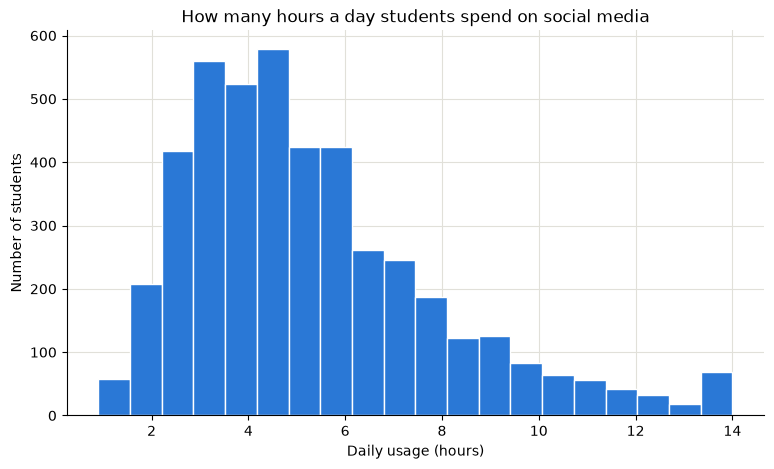

In [11]:
# Overall daily usage
print("Average daily use:", round(df["Daily_Usage_Hours"].mean(), 1), "hours")
print("Median daily use:", round(df["Daily_Usage_Hours"].median(), 1), "hours")
print("Average on a weekend day:", round(df["Weekend_Daily_Hours"].mean(), 1), "hours")

df["Daily_Usage_Hours"].plot(kind="hist", bins=20, color=MAIN_COLOUR, edgecolor="white")
plt.title("How many hours a day students spend on social media")
plt.xlabel("Daily usage (hours)")
plt.ylabel("Number of students")
plt.show()

In [12]:
# Most used platforms, with average daily hours on each
platform_table = (
    df.groupby("Primary_Platform")
    .agg(Students=("Student_ID", "count"), Avg_Daily_Hours=("Daily_Usage_Hours", "mean"))
    .sort_values("Students", ascending=False)
    .round(2)
)
platform_table["Share_%"] = (platform_table["Students"] / len(df) * 100).round(1)
platform_table

,Students,Avg_Daily_Hours,Share_%
Primary_Platform,,,
Instagram,1453,5.26,32.3
TikTok,1226,5.33,27.2
YouTube,818,5.25,18.2
Snapchat,472,5.46,10.5
Reddit,229,5.31,5.1
X (Twitter),206,5.14,4.6
LinkedIn,96,5.27,2.1


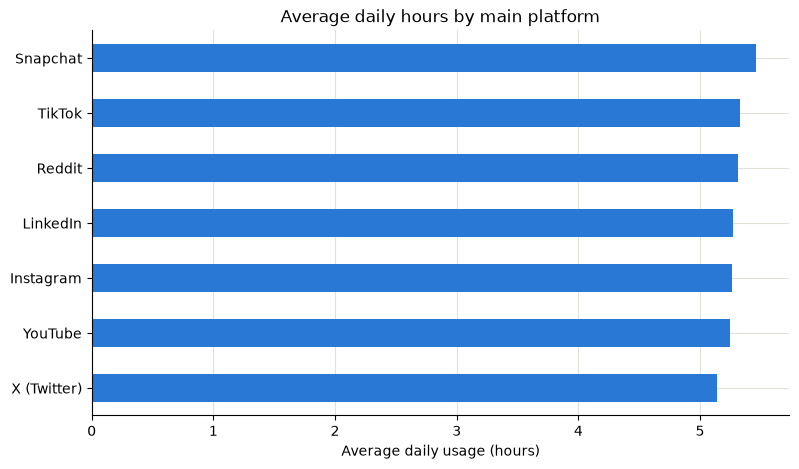

In [13]:
platform_table["Avg_Daily_Hours"].sort_values().plot(kind="barh", color=MAIN_COLOUR)
plt.title("Average daily hours by main platform")
plt.xlabel("Average daily usage (hours)")
plt.ylabel("")
plt.show()

In [14]:
# Usage by academic level and gender
df.pivot_table(
    values="Daily_Usage_Hours",
    index="Academic_Level",
    columns="Gender",
    aggfunc="mean",
).round(2)

Gender,Female,Male,Non-Binary,Prefer not to say
Academic_Level,,,,
High School,5.44,5.20,5.51,5.02
Postgraduate,4.98,5.42,4.02,4.30
Undergraduate,5.29,5.27,5.50,5.54


### Question 2: Is heavier use linked to less sleep, more stress, lower mental health and lower grades?

In [15]:
wellbeing_cols = ["Sleep_Duration_Hours", "Sleep_Quality_Score", "Perceived_Stress_Score",
                  "Mental_Health_Index", "Academic_Performance_GPA"]

usage_group_table = (
    df.groupby("Usage_Group", observed=True)[wellbeing_cols]
    .mean()
    .round(2)
)
usage_group_table["Students"] = df["Usage_Group"].value_counts()
usage_group_table

,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Students
Usage_Group,,,,,,
Light (<3h),7.64,3.39,7.54,91.76,3.72,825
Moderate (3-6h),6.97,2.68,11.90,83.58,3.53,2317
Heavy (>6h),5.66,1.56,19.88,66.33,3.09,1358


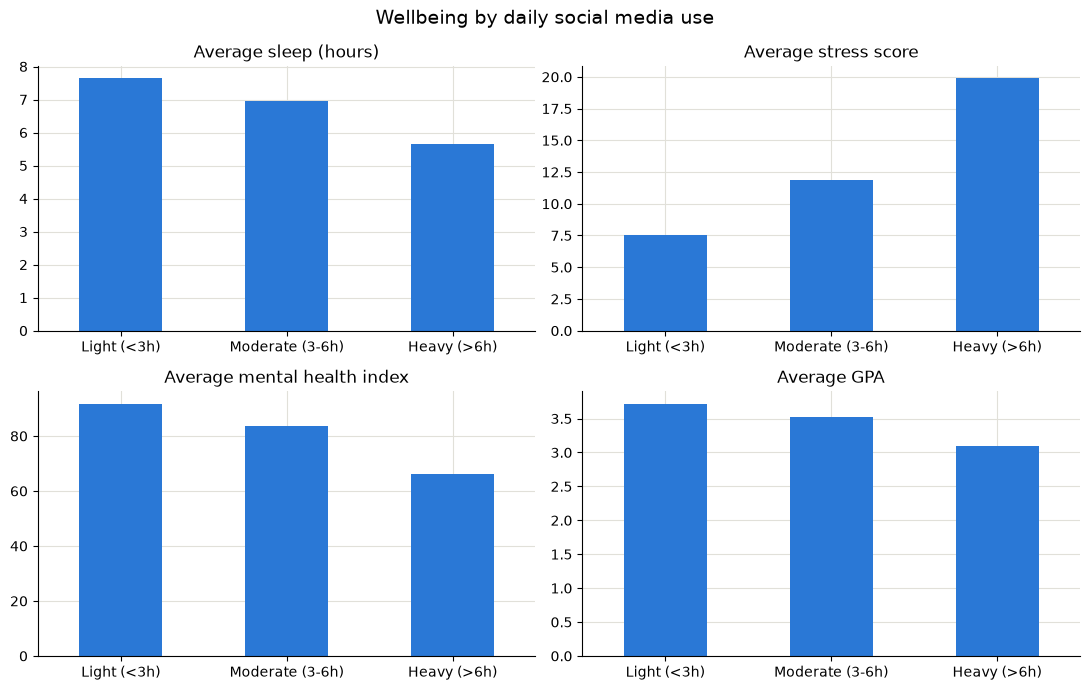

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
charts = [
    ("Sleep_Duration_Hours", "Average sleep (hours)"),
    ("Perceived_Stress_Score", "Average stress score"),
    ("Mental_Health_Index", "Average mental health index"),
    ("Academic_Performance_GPA", "Average GPA"),
]
for ax, (col, title) in zip(axes.flat, charts):
    usage_group_table[col].plot(kind="bar", ax=ax, color=MAIN_COLOUR, rot=0)
    ax.set_title(title)
    ax.set_xlabel("")
fig.suptitle("Wellbeing by daily social media use", fontsize=14)
plt.tight_layout()
plt.show()

In [17]:
# Correlation between daily use and wellbeing (-1 to 1; closer to 0 means a weaker link)
df[["Daily_Usage_Hours"] + wellbeing_cols].corr()["Daily_Usage_Hours"].drop("Daily_Usage_Hours").round(2)

Sleep_Duration_Hours       -0.72
Sleep_Quality_Score        -0.68
Perceived_Stress_Score      0.75
Mental_Health_Index        -0.85
Academic_Performance_GPA   -0.70
Name: Daily_Usage_Hours, dtype: float64

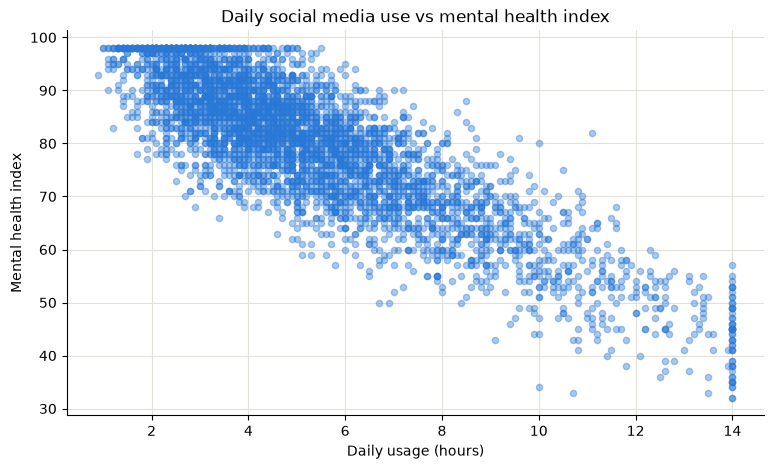

In [18]:
plt.scatter(df["Daily_Usage_Hours"], df["Mental_Health_Index"], alpha=0.4, s=20, color=MAIN_COLOUR)
plt.title("Daily social media use vs mental health index")
plt.xlabel("Daily usage (hours)")
plt.ylabel("Mental health index")
plt.show()

### Question 3: Does late-night use affect sleep?

In [19]:
late_night_table = (
    df.groupby("Late_Night_Usage")
    .agg(
        Students=("Student_ID", "count"),
        Avg_Sleep_Hours=("Sleep_Duration_Hours", "mean"),
        Avg_Sleep_Quality=("Sleep_Quality_Score", "mean"),
        Low_Sleep_Percent=("Low_Sleep", "mean"),
    )
    .rename(index={True: "Uses late at night", False: "No late-night use"})
)
late_night_table["Low_Sleep_Percent"] = late_night_table["Low_Sleep_Percent"] * 100
late_night_table.round(2)

,Students,Avg_Sleep_Hours,Avg_Sleep_Quality,Low_Sleep_Percent
Late_Night_Usage,,,,
No late-night use,1856,7.09,2.81,41.59
Uses late at night,2644,6.43,2.24,65.28


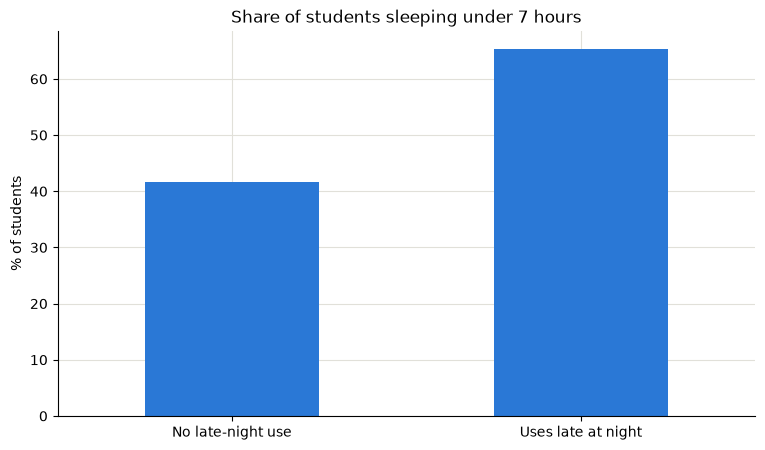

In [20]:
late_night_table["Low_Sleep_Percent"].plot(kind="bar", color=MAIN_COLOUR, rot=0)
plt.title("Share of students sleeping under 7 hours")
plt.ylabel("% of students")
plt.xlabel("")
plt.show()

### Question 4: How does social comparison relate to stress and mental health?

In [21]:
comparison_table = (
    df.groupby("Social_Comparison_Frequency")
    .agg(
        Students=("Student_ID", "count"),
        Avg_Stress=("Perceived_Stress_Score", "mean"),
        Avg_Mental_Health=("Mental_Health_Index", "mean"),
    )
    .reindex(comparison_order)  # least to most frequent
    .round(2)
)
comparison_table

,Students,Avg_Stress,Avg_Mental_Health
Social_Comparison_Frequency,,,
Never,260,13.63,80.52
Rarely,766,13.66,79.41
Sometimes,1594,13.47,79.93
Frequently,1248,13.40,79.94
Always,632,13.58,79.89


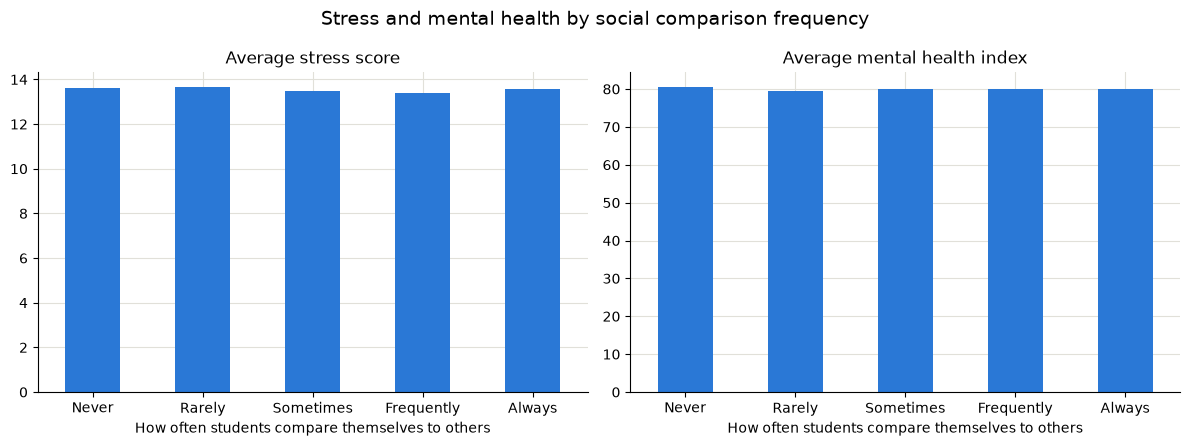

Correlation, comparison vs stress: -0.01
Correlation, comparison vs mental health: 0.0


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
comparison_table["Avg_Stress"].plot(kind="bar", ax=axes[0], color=MAIN_COLOUR, rot=0)
axes[0].set_title("Average stress score")
comparison_table["Avg_Mental_Health"].plot(kind="bar", ax=axes[1], color=MAIN_COLOUR, rot=0)
axes[1].set_title("Average mental health index")
for ax in axes:
    ax.set_xlabel("How often students compare themselves to others")
fig.suptitle("Stress and mental health by social comparison frequency", fontsize=14)
plt.tight_layout()
plt.show()

print("Correlation, comparison vs stress:",
      round(df["Comparison_Score"].corr(df["Perceived_Stress_Score"]), 2))
print("Correlation, comparison vs mental health:",
      round(df["Comparison_Score"].corr(df["Mental_Health_Index"]), 2))

### Question 5: Which platforms are most often linked to a harmful or beneficial impact?

In [23]:
# Percentage of each platform's users in each impact group (each row adds up to 100)
impact_table = pd.crosstab(df["Primary_Platform"], df["Overall_Impact"], normalize="index") * 100

# Put the impact groups in a sensible order: negative, neutral, positive
impact_order = ["Harmful", "Negative", "Neutral", "Positive", "Beneficial"]
impact_cols = [c for c in impact_order if c in impact_table.columns] + \
              [c for c in impact_table.columns if c not in impact_order]
impact_table = impact_table[impact_cols]

sort_col = "Harmful" if "Harmful" in impact_table.columns else impact_table.columns[0]
impact_table = impact_table.sort_values(sort_col)
impact_table.round(1)

Overall_Impact,Negative,Neutral,Beneficial
Primary_Platform,,,
LinkedIn,1.0,20.8,78.1
X (Twitter),1.9,13.6,84.5
Instagram,3.6,14.3,82.1
Snapchat,3.6,16.3,80.1
TikTok,3.9,15.2,80.9
YouTube,4.0,12.7,83.3
Reddit,4.4,13.5,82.1


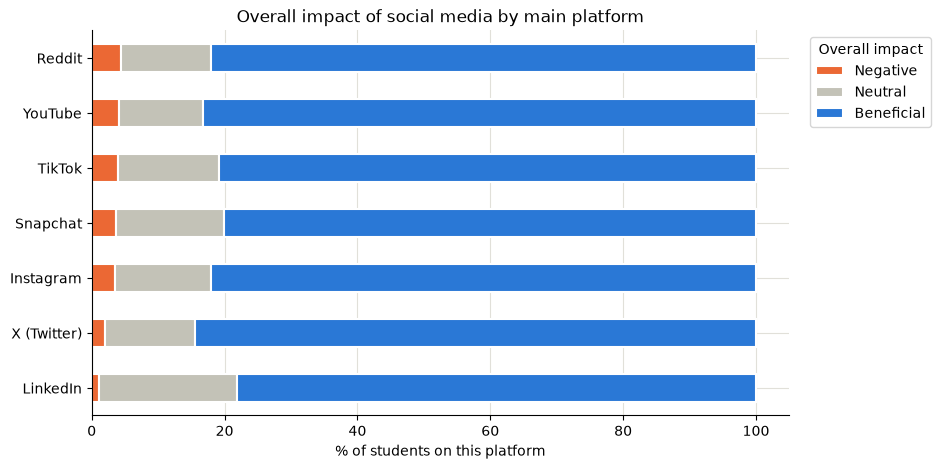

In [24]:
impact_colours = {"Harmful": "#eb6834", "Negative": "#eb6834", "Neutral": "#c3c2b7",
                  "Positive": "#2a78d6", "Beneficial": "#2a78d6"}
colours = [impact_colours.get(c, "#898781") for c in impact_table.columns]

impact_table.plot(kind="barh", stacked=True, color=colours, edgecolor="white", linewidth=1.5)
plt.title("Overall impact of social media by main platform")
plt.xlabel("% of students on this platform")
plt.ylabel("")
plt.legend(title="Overall impact", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

In [25]:
# Average wellbeing for each overall impact group
df.groupby("Overall_Impact")[["Daily_Usage_Hours"] + wellbeing_cols].mean().reindex(impact_cols).round(2)

,Daily_Usage_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
Overall_Impact,,,,,,
Negative,12.25,4.23,1.04,31.01,47.13,2.56
Neutral,8.50,5.48,1.43,22.20,63.42,3.01
Beneficial,4.42,7.03,2.72,11.18,84.26,3.54


## 7. Key findings

The cell below prints the main numbers from the analysis, which I used to write my findings.

In [26]:
heavy = usage_group_table.loc["Heavy (>6h)"] if "Heavy (>6h)" in usage_group_table.index else None
light = usage_group_table.loc["Light (<3h)"] if "Light (<3h)" in usage_group_table.index else None

print(f"1. Students use social media for {df['Daily_Usage_Hours'].mean():.1f} hours a day on average. "
      f"The most common main platform is {platform_table.index[0]} "
      f"({platform_table['Share_%'].iloc[0]}% of students).")

if heavy is not None and light is not None:
    print(f"2. Heavy users sleep {heavy['Sleep_Duration_Hours']:.1f}h vs {light['Sleep_Duration_Hours']:.1f}h for light users, "
          f"with a mental health index of {heavy['Mental_Health_Index']:.1f} vs {light['Mental_Health_Index']:.1f} "
          f"and a GPA of {heavy['Academic_Performance_GPA']:.2f} vs {light['Academic_Performance_GPA']:.2f}.")

lt = late_night_table
if {"Uses late at night", "No late-night use"} <= set(lt.index):
    print(f"3. {lt.loc['Uses late at night', 'Low_Sleep_Percent']:.0f}% of late-night users sleep under 7 hours, "
          f"vs {lt.loc['No late-night use', 'Low_Sleep_Percent']:.0f}% of other students.")

print(f"4. Students who compare themselves '{comparison_table.index[-1]}' have an average stress score of "
      f"{comparison_table['Avg_Stress'].iloc[-1]:.1f}, vs {comparison_table['Avg_Stress'].iloc[0]:.1f} "
      f"for '{comparison_table.index[0]}'.")

print(f"5. The platform with the highest share of '{sort_col}' impact is {impact_table[sort_col].idxmax()} "
      f"({impact_table[sort_col].max():.0f}%), and the lowest is {impact_table[sort_col].idxmin()} "
      f"({impact_table[sort_col].min():.0f}%).")

1. Students use social media for 5.3 hours a day on average. The most common main platform is Instagram (32.3% of students).
2. Heavy users sleep 5.7h vs 7.6h for light users, with a mental health index of 66.3 vs 91.8 and a GPA of 3.09 vs 3.72.
3. 65% of late-night users sleep under 7 hours, vs 42% of other students.
4. Students who compare themselves 'Always' have an average stress score of 13.6, vs 13.6 for 'Never'.
5. The platform with the highest share of 'Negative' impact is Reddit (4%), and the lowest is LinkedIn (1%).


**Findings**

1. **Usage:** Students spend 5.3 hours a day on social media on average, rising to 7.1 hours on weekend days. Instagram (32%) and TikTok (27%) are the most used platforms, but average time barely changes between platforms (5.1 to 5.5 hours). How long students spend online stands out more than which app they use.

2. **Heavy use and wellbeing:** This is the clearest pattern in the data. Compared with light users (under 3 hours a day), heavy users (over 6 hours) sleep about 2 hours less (5.7 vs 7.6), report more than double the stress (19.9 vs 7.5), score 25 points lower on mental health (66 vs 92) and have a lower GPA (3.09 vs 3.72). Moderate users sit in between on every measure, so the link is gradual. From a cyberpsychology point of view, this fits the displacement idea: time online takes the place of sleep, study and offline time.

3. **Late-night use and sleep:** 59% of students use social media late at night. Of those, 65% sleep under 7 hours, compared with 42% of students who don't. Sleep is often described as a key link between screen use and mood, so late-night use might be a more useful thing to change than total screen time.

4. **Social comparison:** This was the most surprising result. How often students compare themselves to others made almost no difference to stress: 13.6 for those who never compare and 13.6 for those who always do, with a correlation close to zero (-0.01). Social comparison theory would predict the opposite. One explanation is that the data only measures how often students compare, not who they compare themselves with or how it makes them feel. Upward comparison (with people who seem better than them) is the type usually linked to harm, and this question can't separate it out.

5. **Platforms:** Platform made little difference. On every platform, 78% to 85% of users fall into the beneficial impact group, and the negative share stays under 5%. LinkedIn has the lowest negative share (1%), but with only 96 users that result isn't reliable. There is also a gap: 30% of students are heavy users, yet under 4% fall into the negative group. If this label reflects how students see themselves, it suggests people may not notice harm that builds slowly, especially when an app feels useful day to day.

**Overall:** In this dataset, how much and when students use social media matters far more than which platform they use or how often they compare themselves to others. One thing I would flag is that the links are very strong (a correlation of -0.85 between daily use and mental health). Large studies usually find much weaker links between screen time and wellbeing, so this dataset may be simplified or generated. The next step would be to test the same questions on real survey data.

## 8. Limitations and next steps

**Limitations**
- The data is self-reported, so people may under or overestimate their usage and wellbeing.
- It only covers students, so the results may not apply to other age groups.
- These are correlations, not causes. For example, stressed students might use social media more, rather than social media causing stress.
- The dataset does not explain exactly how the stress, sleep quality and mental health scores were measured.
- I compared group averages and correlations only. I did not test whether the differences are statistically significant.
- Missing stress (46 rows) and GPA (85 rows) values were filled with the median, which may slightly reduce differences between groups.
- Some groups are small (96 LinkedIn users, 246 postgraduates), so their results are less reliable.
- The relationships are much stronger than in most published research, which suggests the data may be synthetic.